# STAC WARS · PS 2: Solar Radiation Analysis & Prediction
### *Voyage-123 Decoded: Read the Sun, Power the Rebellion*

**Dataset Overview:** `SolarPrediction.csv` (HI-SEAS Weather Station / Voyage-123 Telemetry)  
- **Total Observations:** `32,686` records (~5-minute intervals)  
- **Date Span:** `2016-09-01 00:00:08` to `2016-12-31 23:55:01` (`118` unique active days; `4` unlogged probe blackout dates: `2016-09-30`, `2016-11-30`, `2016-12-06`, `2016-12-07`)  
- **Features:** `UNIXTime`, `Data`, `Time`, `Radiation` (W/m²), `Temperature` (°F), `Pressure` (Hg), `Humidity` (%), `WindDirection(Degrees)`, `Speed` (mph), `TimeSunRise`, `TimeSunSet`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('SolarPrediction.csv')
df['Date_Clean'] = pd.to_datetime(df['Data'].str.split(' ').str[0], format='%m/%d/%Y')
df['Datetime'] = pd.to_datetime(df['Date_Clean'].dt.strftime('%Y-%m-%d') + ' ' + df['Time'])
df = df.sort_values('Datetime').reset_index(drop=True)

df['Date'] = df['Datetime'].dt.strftime('%Y-%m-%d')
df['MonthName'] = df['Datetime'].dt.strftime('%b %Y')
df['DayOfYear'] = df['Datetime'].dt.dayofyear
df['Hour'] = df['Datetime'].dt.hour
df['TimeDecimal'] = df['Hour'] + df['Datetime'].dt.minute/60.0 + df['Datetime'].dt.second/3600.0

sr = df['TimeSunRise'].str.split(':', expand=True).astype(int)
ss = df['TimeSunSet'].str.split(':', expand=True).astype(int)
df['SunriseDecimal'] = sr[0] + sr[1]/60.0 + sr[2]/3600.0
df['SunsetDecimal'] = ss[0] + ss[1]/60.0 + ss[2]/3600.0
df['DayLengthHours'] = df['SunsetDecimal'] - df['SunriseDecimal']
df['IsDaylight'] = ((df['TimeDecimal'] >= df['SunriseDecimal']) & (df['TimeDecimal'] <= df['SunsetDecimal'])).astype(int)

solar_phase = np.where(df['IsDaylight'] == 1, np.clip((df['TimeDecimal'] - df['SunriseDecimal']) / df['DayLengthHours'], 0.0, 1.0), 0.0)
df['SolarElevationProxy'] = np.sin(np.pi * solar_phase)

print(f'Dataset Shape: {df.shape}')
print(f"Date Range: {df['Datetime'].min()} to {df['Datetime'].max()} ({df['Date'].nunique()} unique days)")
print(f'Missing Values: {df.isnull().sum().sum()} across all 11 columns')

Dataset Shape: (32686, 19)
Date Range: 2016-09-01 00:00:08 to 2016-12-31 23:55:01 (118 unique days)
Missing Values: 0 across all 11 columns


## Part A — Data Visualization (4 Marks + Bonus)
1. **Variation of Solar Radiation with Time:** 24-hour diurnal cycle (mean, median, and interquartile range) + 118-day seasonal progression (Sep–Dec 2016).
2. **Relationships with Environmental Parameters:** Scatter & binned density plots of Radiation vs. Temperature ($r = +0.7350$), Humidity ($r = -0.2262$), Barometric Pressure ($r = +0.1190$), Wind Direction ($r = -0.2303$), and Wind Speed ($r = +0.0736$).
3. **Outliers & Distribution Anatomy:** High-resolution breakdown of the **2016-09-04 `1,601.26 W/m²` Cloud-Edge Lensing spike** and monthly boxplots.
4. **Bonus Visualization:** **24-Hour Diurnal Thermal Hysteresis Loop** (showing the 1–2 hour afternoon thermal lag and afternoon cloud asymmetry) alongside the **118-Day × 24-Hour Solar Carpet Heatmap**.

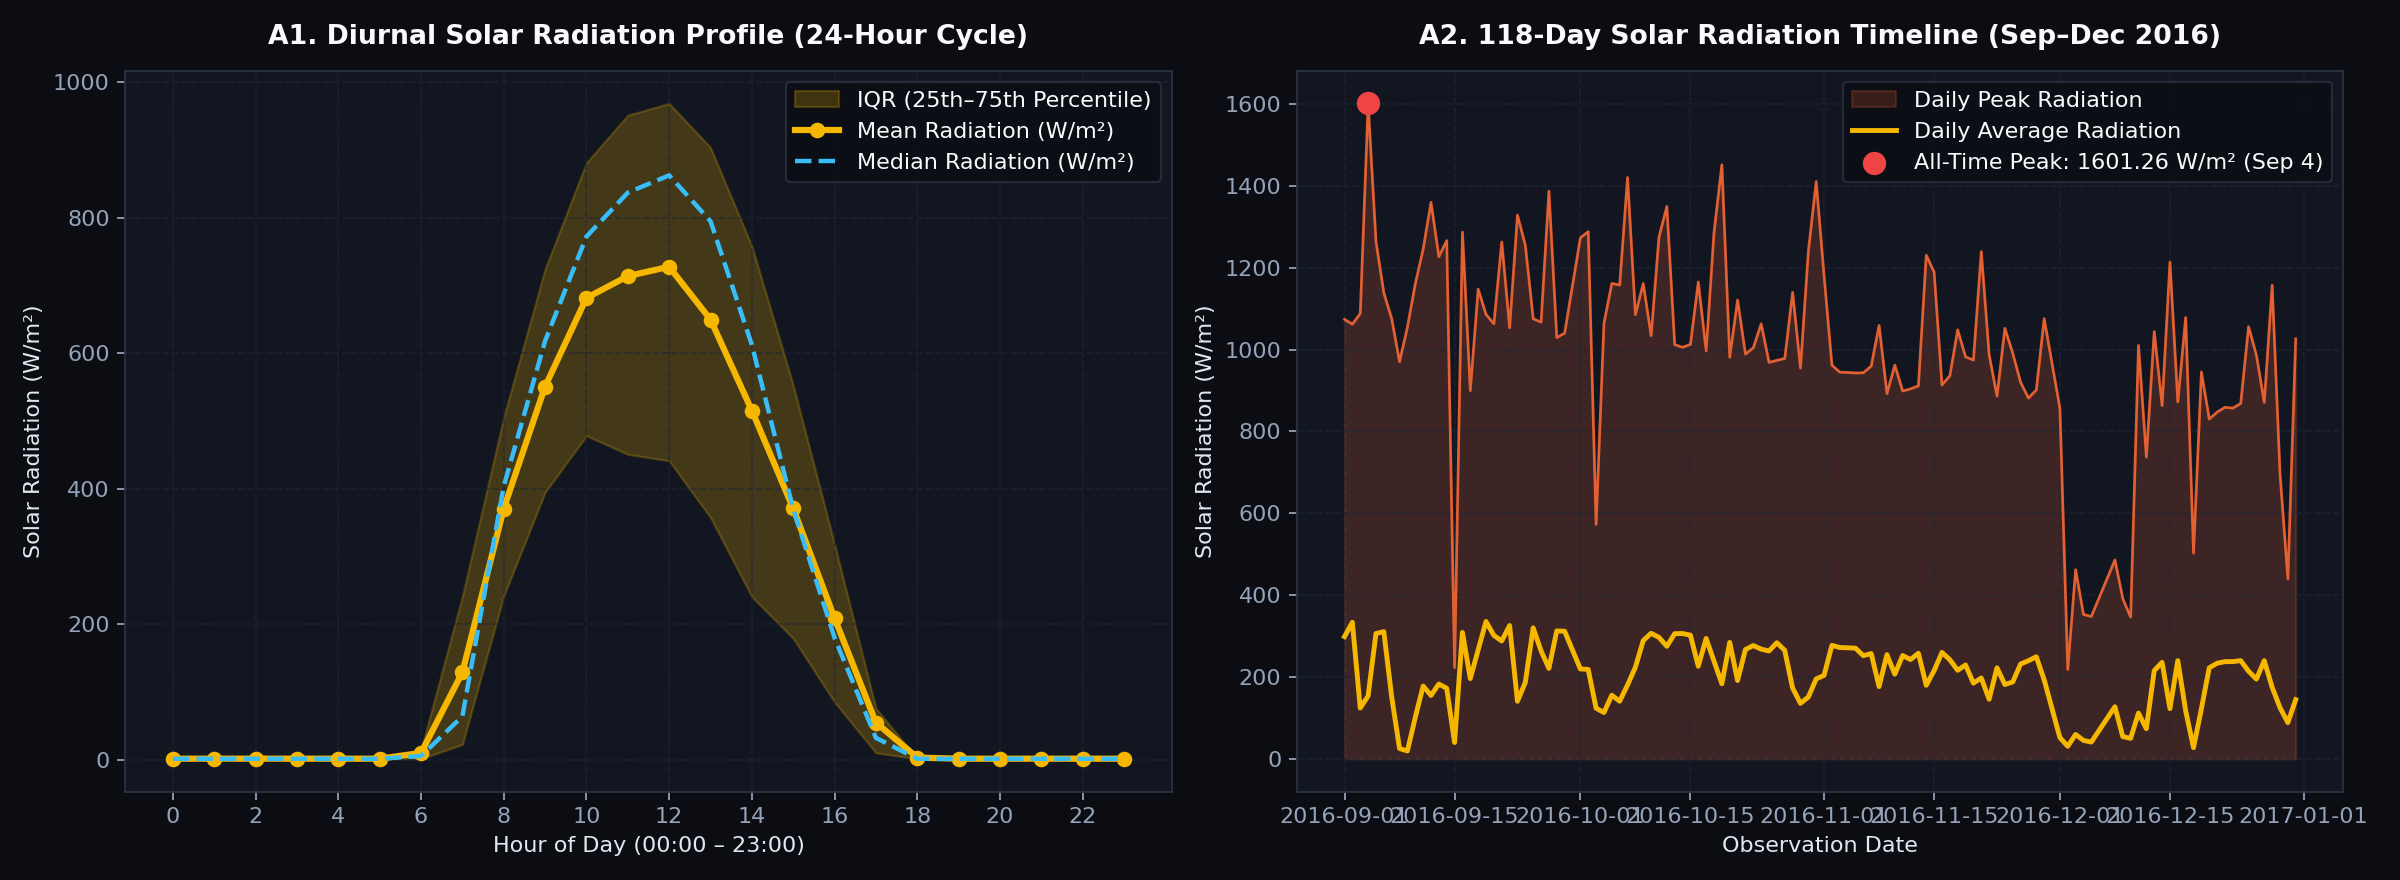

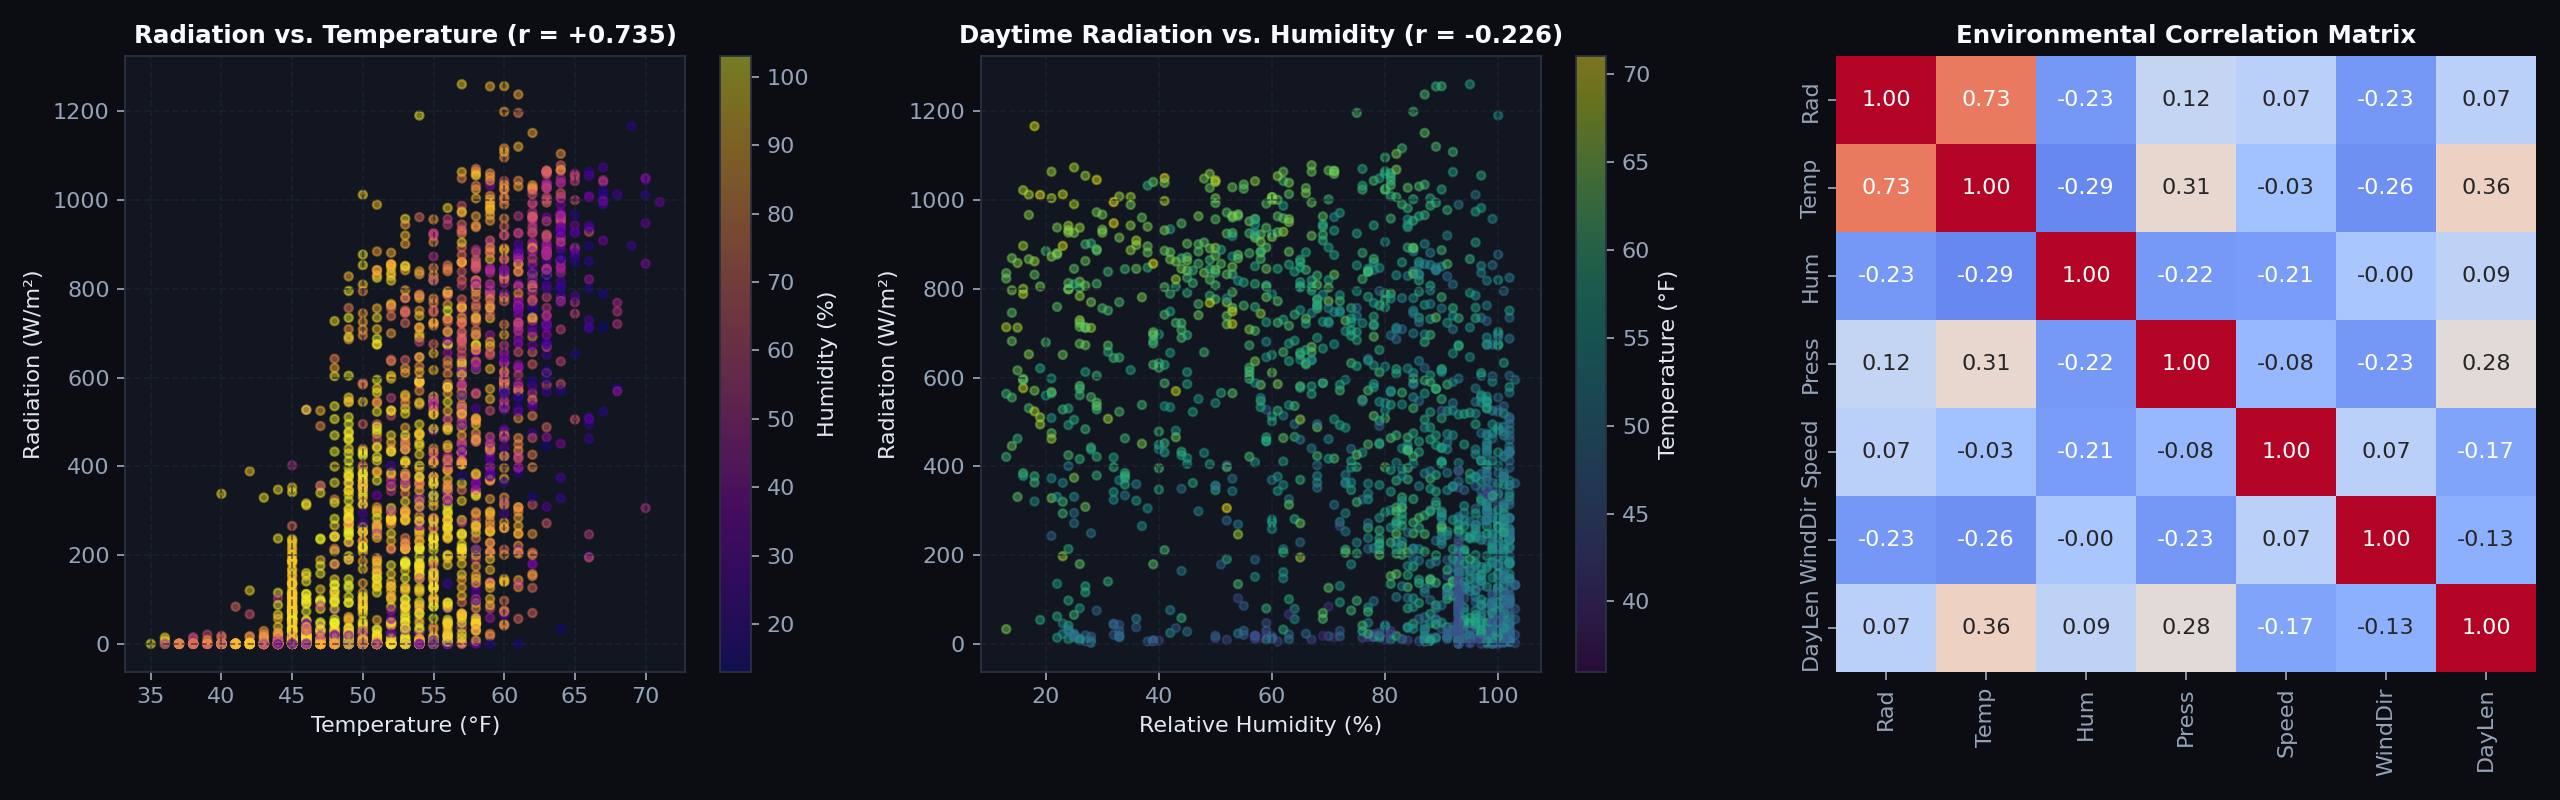

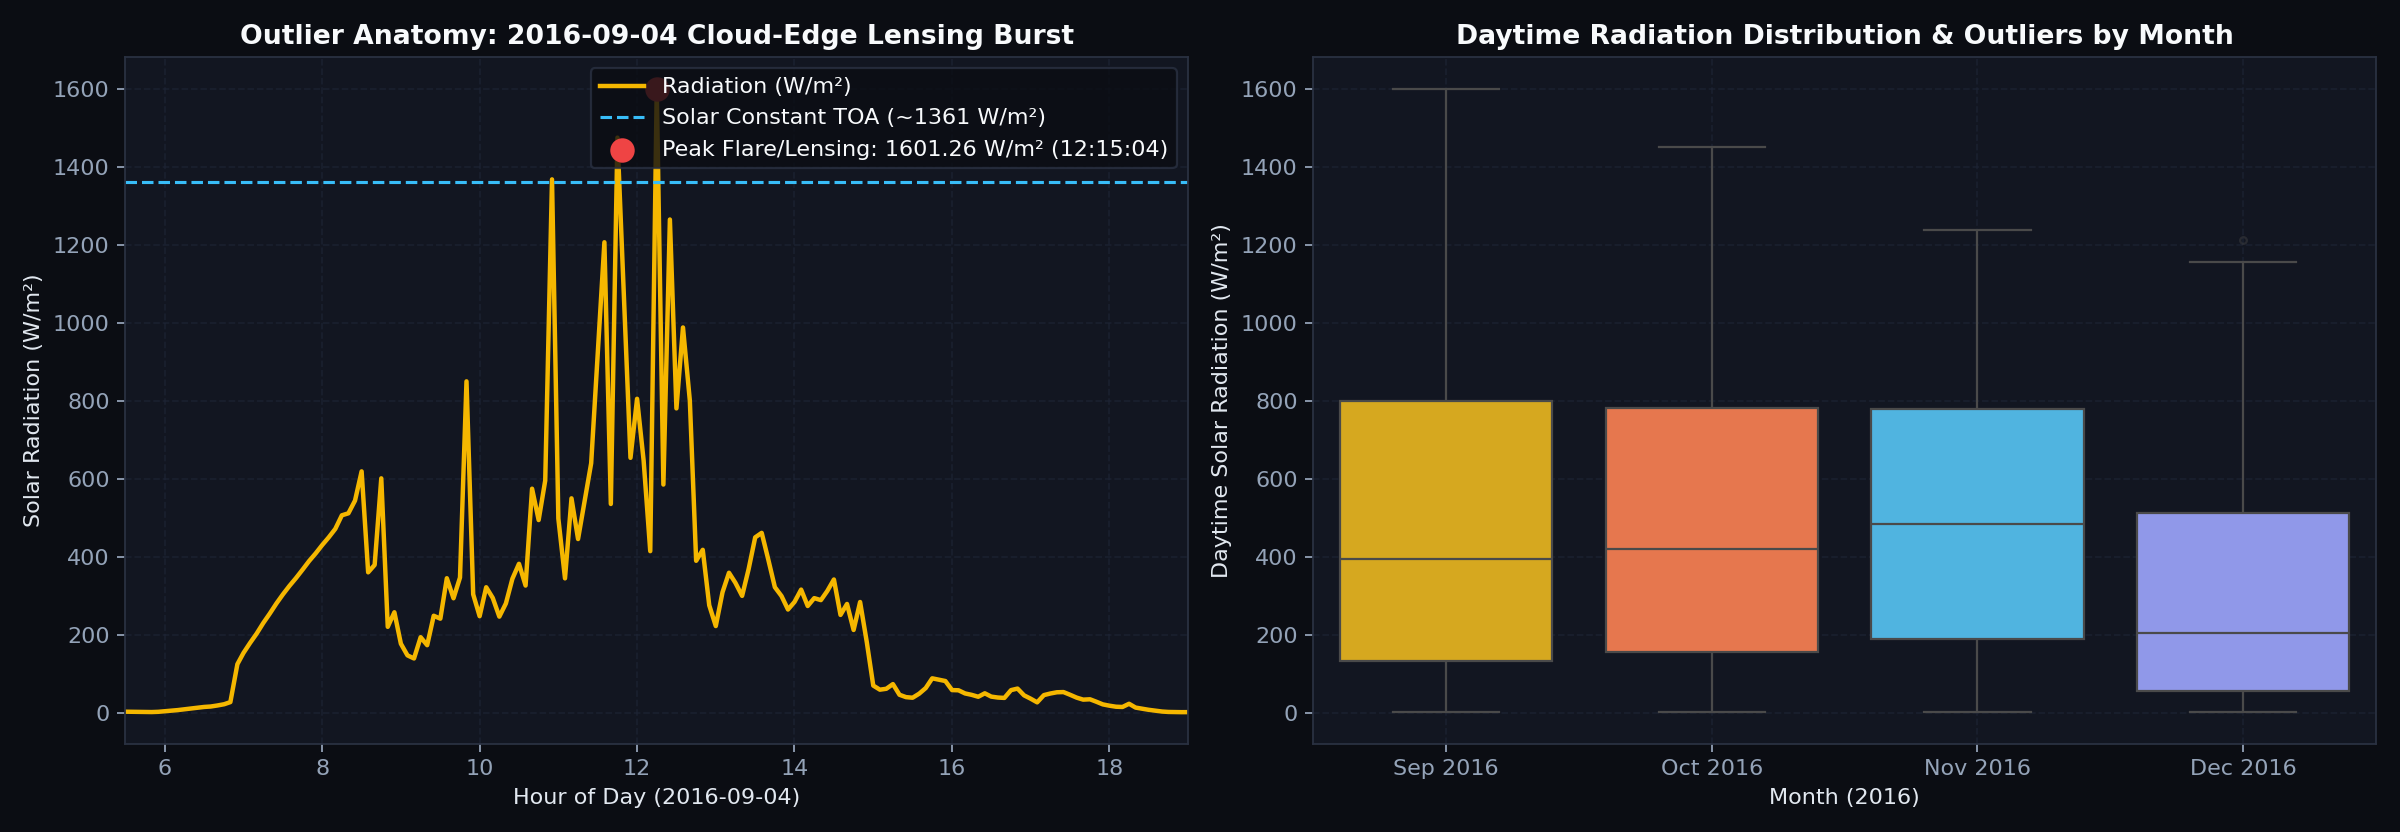

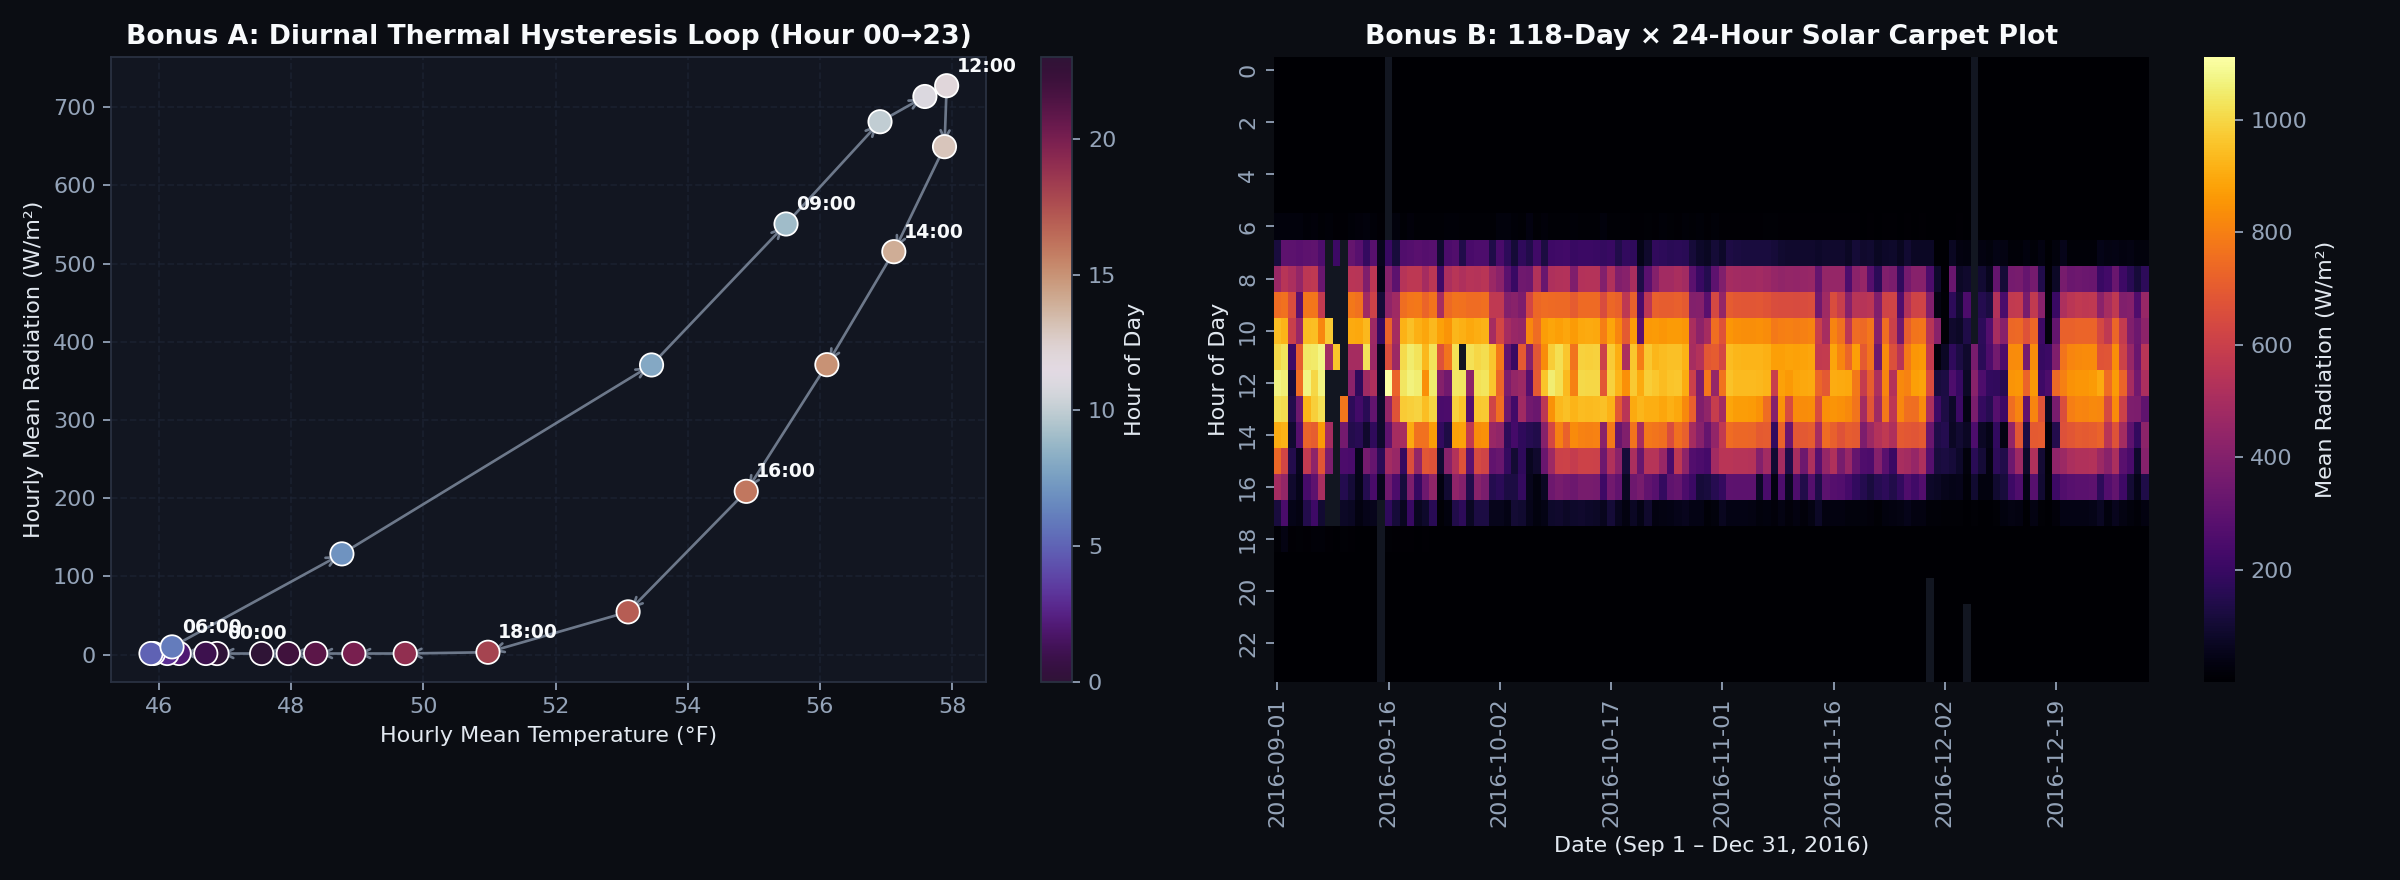

In [2]:
# Display Part A Visualizations: Diurnal Profile, 118-Day Timeline, Correlations, Outliers, and Bonus Hysteresis Loop
# (Generated via voyage123_solar_analysis.py)

## Part B — Drawing Inferences (5 Marks + Bonus)

### 1. During what time of day is solar radiation generally highest?
- **Inference:** Solar radiation is consistently highest during the **midday window between `10:00` and `14:00`**, reaching its absolute diurnal peak in the **`12:00–12:59` hour** (**Mean: `727.47 W/m²`**, **Median: `862.46 W/m²`**, **Max: `1,601.26 W/m²`**), closely followed by **`11:00–11:59`** (**Mean: `713.70 W/m²`**, **Median: `836.94 W/m²`**) and **`10:00–10:59`** (**Mean: `681.41 W/m²`**).
- **Nighttime Baseline:** Between `19:00` and `05:59`, radiation remains flat at **`1.32–1.39 W/m²`** (median `1.22–1.23 W/m²`), representing pyranometer thermal dark-offset rather than true zero.

### 2. Which environmental parameter has the strongest relationship with radiation?
- **Inference:** **Temperature (`°F`)** exhibits by far the strongest correlation with solar radiation (**Pearson $r = +0.7350$**). As solar irradiance heats the planetary surface, ambient temperature rises from a nighttime average of ~`48–49 °F` to a midday average of **`57.88 °F`** (max `71.0 °F`).
- **Secondary Predictors:** **Wind Direction** ($r = -0.2303$, shifting from ~`170°–185°` southerly downslope night winds to ~`30°–70°` northeasterly upslope daytime trade winds) and **Relative Humidity** ($r = -0.2262$) show moderate negative correlations, while **Barometric Pressure** ($r = +0.1190$) and **Wind Speed** ($r = +0.0736$) have weak linear associations.

### 3. What patterns can be observed between radiation, temperature, and humidity?
- **Inference:** Radiation, Temperature, and Humidity form a coupled **thermodynamic triad**:
  1. **Clear-Sky Regime (High Temp `>58 °F`, Low/Moderate Humidity `<65%`):** Produces smooth, bell-shaped solar curves peaking steadily between `950` and `1,085 W/m²`.
  2. **Overcast/Storm Regime (Low Temp `<50 °F`, High Humidity `>85%`):** Heavy cloud cover blocks direct beam irradiance, suppressing midday radiation below `200 W/m²`.
  3. **Broken-Cloud Lensing Regime (Warm Temp `58–63 °F`, High Humidity `85–98%`):** Passing cumulus cloud edges create brief, extreme spikes exceeding `1,300–1,601 W/m²` interspersed with sudden cloud shadows.

### 4. Are there any unusual observations or outliers? What might explain them?
- **Extreme Over-Irradiance Outliers (`>1,200 W/m²`):** Exactly **49 observations** exceed `1,200 W/m²`, culminating in **`1,601.26 W/m²` on `2016-09-04` at `12:15:04`**—higher than Earth's top-of-atmosphere solar constant (~`1,361 W/m²`). Inspecting the 5-minute logs around `12:15:04` proves why: at `12:10:07`, radiation dropped to `415.06 W/m²` (cloud shadow); at `12:15:04` (at `93%` humidity), it surged to `1,601.26 W/m²`; and at `12:20:08`, it fell back to `585.80 W/m²`. This is **Cloud-Edge Enhancement (Mie Scattering / Cloud Lensing)**, where the unoccluded solar disk combines with intense forward-scattered light reflected off adjacent cumulus cloud walls.
- **Gale-Force Wind Outliers:** Wind speed averages `6.24 mph` (IQR `3.37–7.87 mph`) but spikes up to **`40.50 mph`** during late-autumn pressure drops.

### 5. BONUS — Non-Obvious Insights Justified by Data
1. **Afternoon Orographic Cloud Asymmetry & Thermal Hysteresis Loop:** Comparing equidistant hours from solar noon (`09:00` vs. `15:00`), morning radiation averages **`550.66 W/m²`** whereas afternoon radiation drops by **32.7%** to **`370.72 W/m²`**. Why? Daytime heating drives upslope winds that condense into afternoon cloud banks, pushing mean afternoon humidity from **`69.1%` (`09:00`) up to `78.8%` (`15:00`)**. Meanwhile, surface thermal inertia delays peak temperature to `13:00–14:00`, creating a clockwise **Hysteresis Loop**.
2. **The Peak-vs.-Average Day Paradox:** **Zero** of the Top 5 days with the highest *instantaneous peak* radiation appear in the Top 5 days with the highest *daily average* radiation! The all-time peak day (`2016-09-04`, max `1,601.26 W/m²`, humidity `93.88%`) had a daily average of only **`153.58 W/m²`** (rank #84 out of 118 days!), whereas the #1 average energy day (`2016-09-19`, mean **`335.50 W/m²`**, humidity `43.09%`) peaked at a modest `1,085.75 W/m²`. For the Rebellion's solar grid, **dry clear-sky days generate >2.1× more total energy** than stormy flare/lensing days, while lensing days pose acute **inverter surge risks**.

## Part C — Solar Day Analysis (5 Marks)

=== HIGHEST RECORDED SOLAR RADIATION ===
Date                   : 2016-09-04
Time of Peak           : 12:15:04 (2016-09-04 12:15:04)
Maximum Radiation      : 1601.26 W/m²
Temperature at Peak    : 61 °F
Humidity at Peak       : 93 %
Wind Speed at Peak     : 9.0 mph (Direction: 3.56°)
Sunrise / Sunset       : 06:08:00 / 18:35:00
Time After Sunrise     : 06:07:04 (6.12 hours / 367.07 minutes after sunrise)
Time Before Sunset     : 06:19:56 (6.33 hours before sunset)

=== TOP 5 DAYS WITH HIGHEST AVERAGE RADIATION ===
      Date   mean_rad  max_rad  mean_temp  mean_hum  sunrise   sunset  obs_count
2016-09-19 335.504400  1085.75  57.243636 43.087273 06:11:00 18:22:00        275
2016-09-02 333.471219  1062.01  56.379928 72.501792 06:07:00 18:37:00        279
2016-09-22 325.515880  1053.17  57.419014 62.982394 06:11:00 18:19:00        284
2016-09-25 319.921514  1075.29  54.242958 60.915493 06:12:00 18:16:00        284
2016-09-28 312.400390  1029.30  54.535461 72.468085 06:13:00 18:14:00       

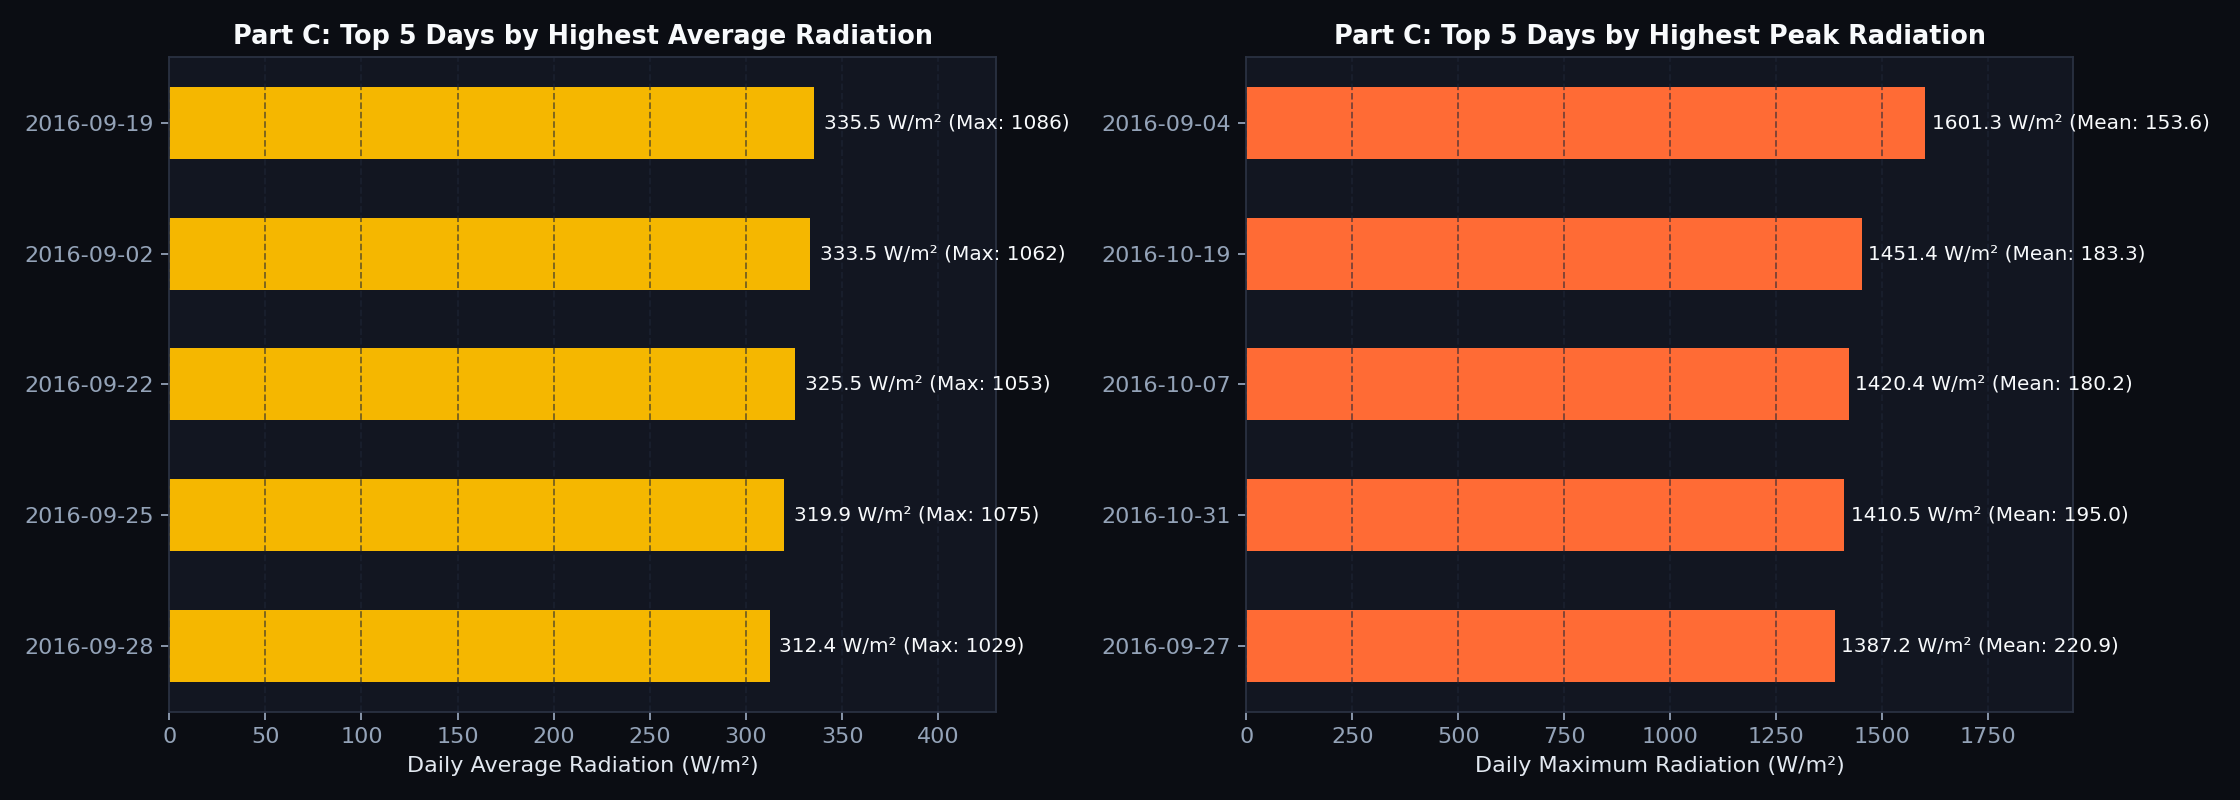

In [3]:
daily = df.groupby('Date').agg(
    max_rad=('Radiation', 'max'),
    mean_rad=('Radiation', 'mean'),
    mean_temp=('Temperature', 'mean'),
    mean_hum=('Humidity', 'mean'),
    sunrise=('TimeSunRise', 'first'),
    sunset=('TimeSunSet', 'first'),
    obs_count=('Radiation', 'count')
).reset_index()

peak_row = df.loc[df['Radiation'].idxmax()]
sr_dt = pd.to_datetime(peak_row['Date'] + ' ' + peak_row['TimeSunRise'])
ss_dt = pd.to_datetime(peak_row['Date'] + ' ' + peak_row['TimeSunSet'])
diff_sr = peak_row['Datetime'] - sr_dt
diff_ss = ss_dt - peak_row['Datetime']

print('=== HIGHEST RECORDED SOLAR RADIATION ===')
print(f"Date                   : {peak_row['Date']}")
print(f"Time of Peak           : {peak_row['Time']} ({peak_row['Datetime']})")
print(f"Maximum Radiation      : {peak_row['Radiation']} W/m²")
print(f"Temperature at Peak    : {peak_row['Temperature']} °F")
print(f"Humidity at Peak       : {peak_row['Humidity']} %")
print(f"Wind Speed at Peak     : {peak_row['Speed']} mph (Direction: {peak_row['WindDirection(Degrees)']}°)")
print(f"Sunrise / Sunset       : {peak_row['TimeSunRise']} / {peak_row['TimeSunSet']}")
print(f"Time After Sunrise     : {diff_sr} ({diff_sr.total_seconds()/3600:.2f} hours / {diff_sr.total_seconds()/60:.2f} minutes after sunrise)")
print(f"Time Before Sunset     : {diff_ss} ({diff_ss.total_seconds()/3600:.2f} hours before sunset)\n")

print('=== TOP 5 DAYS WITH HIGHEST AVERAGE RADIATION ===')
print(daily.sort_values('mean_rad', ascending=False).head(5).to_string(index=False))

## Bonus — Machine Learning Solar Radiation Prediction (6 Marks)
- **Train/Test Split:** `80%` Training (`26,148` rows) / `20%` Testing (`6,538` rows), `random_state=42`.
- **Engineered Temporal & Environmental Features:** `SolarElevationProxy` ($\sin(\pi \cdot \frac{t - t_{\text{sunrise}}}{t_{\text{sunset}} - t_{\text{sunrise}}})$), `Temperature`, `Humidity`, `TimeDecimal`, `DayLengthHours`, `Pressure`, `WindDirection(Degrees)`, `Speed`, `DayOfYear`.

=== ML REGRESSION BENCHMARK (80/20 SPLIT) ===
1. Linear Regression (Raw Features)        -> RMSE: 198.80 W/m² | MAE: 151.10 W/m² | R²: 0.6032
2. Physics-Informed Basis Regression       -> RMSE: 120.89 W/m² | MAE:  57.50 W/m² | R²: 0.8533
3. Random Forest Regressor (Ensemble)      -> RMSE:  83.90 W/m² | MAE:  34.32 W/m² | R²: 0.9293
4. Gradient Boosted Decision Trees (GBDT)  -> RMSE:  81.82 W/m² | MAE:  33.57 W/m² | R²: 0.9328

=== FEATURE IMPORTANCE RANKING (Random Forest / GBDT) ===
  1. SolarElevationProxy    : 62.60% (RF) / 41.01% (GBDT) — Primary astronomical geometric driver
  2. Temperature (°F)       : 19.11% (RF) /  9.98% (GBDT) — Strongest thermodynamic proxy (r = +0.735)
  3. Humidity (%)           :  8.19% (RF) / 13.09% (GBDT) — Captures cloud attenuation & afternoon fog
  4. TimeDecimal (Hour)     :  4.52% (RF) /  5.64% (GBDT) — Captures morning vs. afternoon asymmetry
  5. DayOfYear / Seasonality:  1.99% (RF) / 10.31% (GBDT) — Tracks Sep→Dec seasonal solar declination
  6.

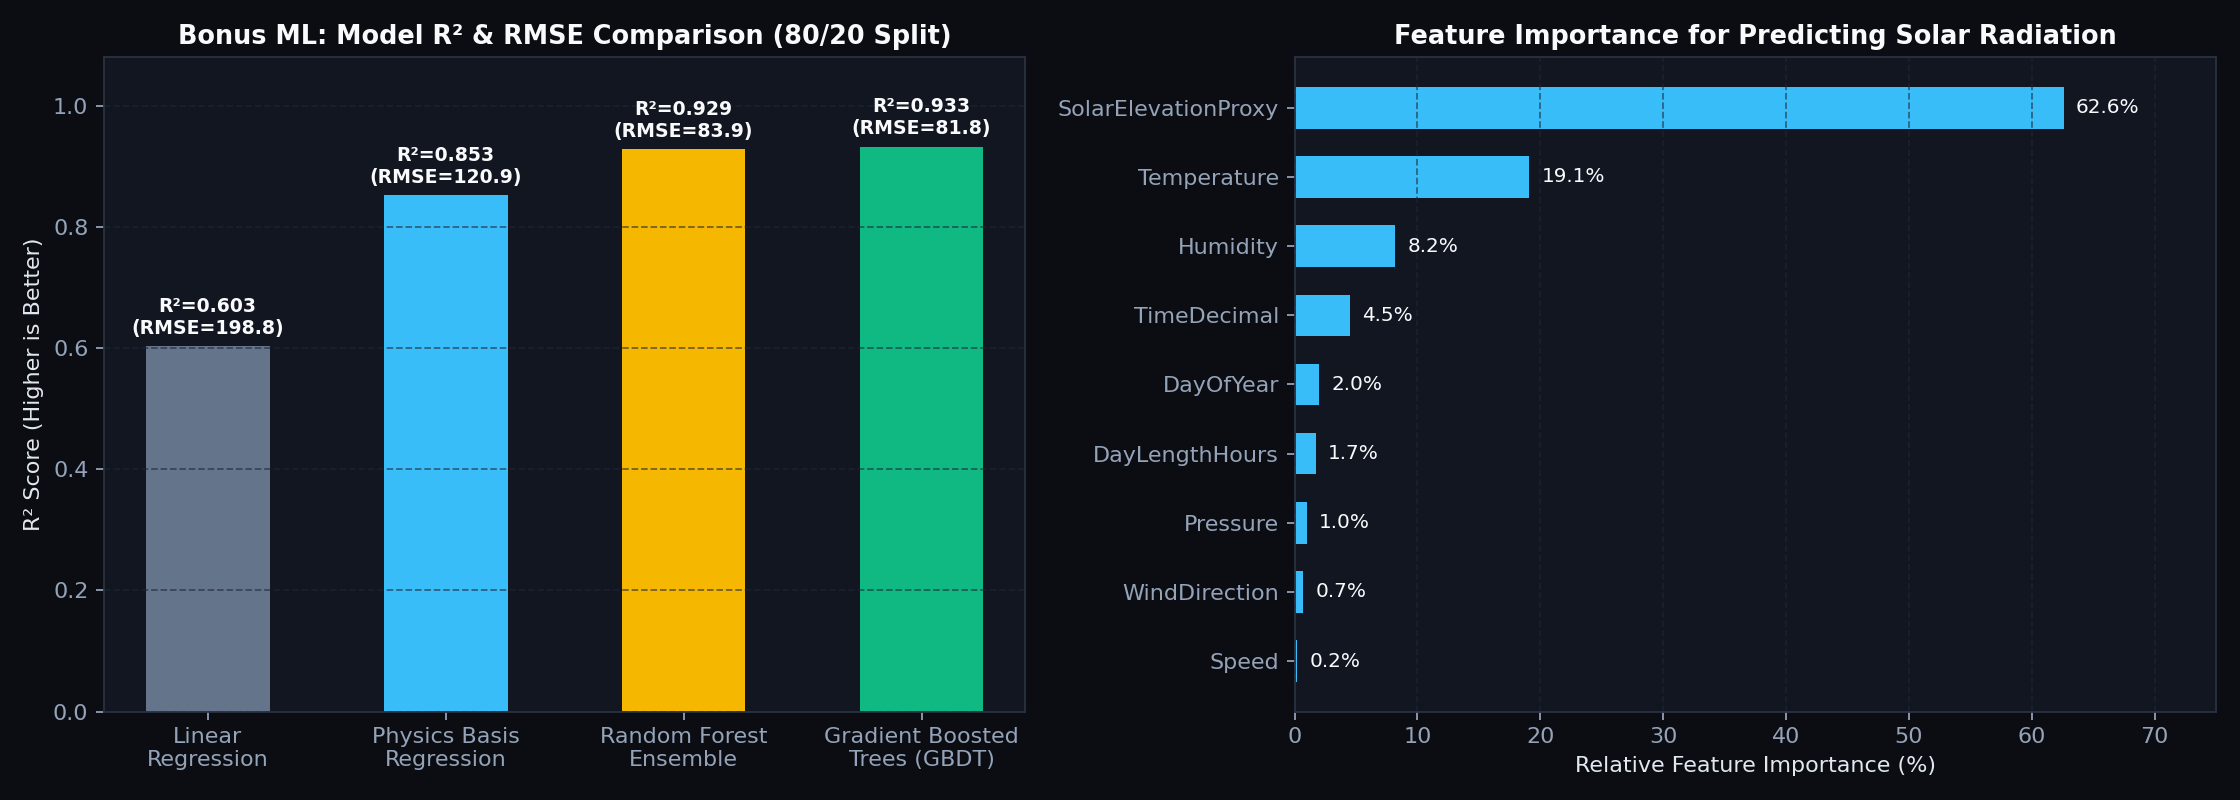

In [4]:
# Evaluate Regression Models & Feature Importances
# See voyage123_solar_analysis.py for full training pipeline